
# EVChargeIQ
## Machine Learning Model Development

### Objective
To develop and evaluate machine learning regression models for estimating subsequent-year EV public charging infrastructure installations across Indian states and union territories.

### Dataset
Processed state-year charging infrastructure dataset generated during Notebook 01.

### Input Features
- State
- Year Index
- Current Year Installations
- Cumulative Installations

### Target Variable
Next Year Installations

### Algorithms
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [16]:

possible_paths = [
    Path.cwd() / "data" / "processed" / "ml_training_dataset.csv",
    Path.cwd().parent / "data" / "processed" / "ml_training_dataset.csv"
]

ML_DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if ML_DATA_PATH is None:
    raise FileNotFoundError(
        "ml_training_dataset.csv not found. Run Notebook 01 first."
    )

ml_df = pd.read_csv(ML_DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", ml_df.shape)

display(ml_df.head(10))


Dataset loaded successfully!
Shape: (144, 5)


,state,year_index,current_installations,cumulative_installations,next_year_installations
0,Andaman and Nicobar,0,0,0,2
1,Andaman and Nicobar,1,2,2,0
2,Andaman and Nicobar,2,0,2,1
3,Andaman and Nicobar,3,1,3,2
4,Andhra Pradesh,0,1,1,133
5,Andhra Pradesh,1,133,134,143
6,Andhra Pradesh,2,143,277,360
7,Andhra Pradesh,3,360,637,624
8,Arunachal Pradesh,0,2,2,6
9,Arunachal Pradesh,1,6,8,23


In [17]:


FEATURE_COLUMNS = [
    "state",
    "year_index",
    "current_installations",
    "cumulative_installations"
]

TARGET_COLUMN = "next_year_installations"

X = ml_df[FEATURE_COLUMNS]
y = ml_df[TARGET_COLUMN]

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing Values:")
display(ml_df[FEATURE_COLUMNS + [TARGET_COLUMN]].isnull().sum())


Input Features:


,state,year_index,current_installations,cumulative_installations
0,Andaman and Nicobar,0,0,0
1,Andaman and Nicobar,1,2,2
2,Andaman and Nicobar,2,0,2
3,Andaman and Nicobar,3,1,3
4,Andhra Pradesh,0,1,1



Target Variable:


0      2
1      0
2      1
3      2
4    133
Name: next_year_installations, dtype: int64


Feature Shape: (144, 4)
Target Shape: (144,)

Missing Values:


state                       0
year_index                  0
current_installations       0
cumulative_installations    0
next_year_installations     0
dtype: int64

In [18]:

# Training: FY20-21, FY21-22 and FY22-23 feature periods
train_df = ml_df[
    ml_df["year_index"] <= 2
].copy()

# Testing: FY23-24 feature period, predicting FY24-25
test_df = ml_df[
    ml_df["year_index"] == 3
].copy()

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET_COLUMN]

X_test = test_df[FEATURE_COLUMNS]
y_test = test_df[TARGET_COLUMN]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining year indices:")
print(sorted(train_df["year_index"].unique()))

print("\nTesting year indices:")
print(sorted(test_df["year_index"].unique()))

print("\nTraining states:", train_df["state"].nunique())
print("Testing states:", test_df["state"].nunique())


Training records: 108
Testing records: 36

Training year indices:
[np.int64(0), np.int64(1), np.int64(2)]

Testing year indices:
[np.int64(3)]

Training states: 36
Testing states: 36


In [19]:

categorical_features = ["state"]

numerical_features = [
    "year_index",
    "current_installations",
    "cumulative_installations"
]

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [20]:

linear_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_predictions = np.maximum(
    linear_predictions,
    0
)

print("Linear Regression trained successfully!")

print("\nFirst 10 predictions:")
display(linear_predictions[:10])


Linear Regression trained successfully!

First 10 predictions:


array([ 10.585233  , 616.50380069,  62.32891831, 359.72490268,
       412.13769043,  20.441353  , 334.12018601, 214.46525441,
        54.78922947, 904.72794471])

In [21]:

decision_tree_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=5,
                random_state=42
            )
        )
    ]
)

decision_tree_model.fit(X_train, y_train)

decision_tree_predictions = decision_tree_model.predict(
    X_test
)

decision_tree_predictions = np.maximum(
    decision_tree_predictions,
    0
)

print("Decision Tree Regressor trained successfully!")

display(decision_tree_predictions[:10])


Decision Tree Regressor trained successfully!


array([ 13.90697674, 497.5       ,  31.        , 357.57142857,
       357.57142857,  13.90697674, 357.57142857, 193.75      ,
        31.        , 343.        ])

In [22]:

random_forest_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=150,
                max_depth=6,
                random_state=42
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

random_forest_predictions = random_forest_model.predict(
    X_test
)

random_forest_predictions = np.maximum(
    random_forest_predictions,
    0
)

print("Random Forest Regressor trained successfully!")

display(random_forest_predictions[:10])


Random Forest Regressor trained successfully!


array([ 11.4809662 , 523.81981339,  34.98117246, 357.63095312,
       365.68912243,  12.63671995, 364.52539757, 223.07695518,
        47.28662434, 657.22524074])

In [23]:

def evaluate_model(actual, predicted, model_name):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


results = []

results.append(
    evaluate_model(
        y_test,
        linear_predictions,
        "Linear Regression"
    )
)

results.append(
    evaluate_model(
        y_test,
        decision_tree_predictions,
        "Decision Tree"
    )
)

results.append(
    evaluate_model(
        y_test,
        random_forest_predictions,
        "Random Forest"
    )
)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE"
).reset_index(drop=True)

display(results_df.round(3))


,Model,MAE,MSE,RMSE,R2
0,Random Forest,91.912,17851.199,133.608,0.847
1,Decision Tree,111.568,33376.544,182.692,0.715
2,Linear Regression,123.884,52266.768,228.619,0.553


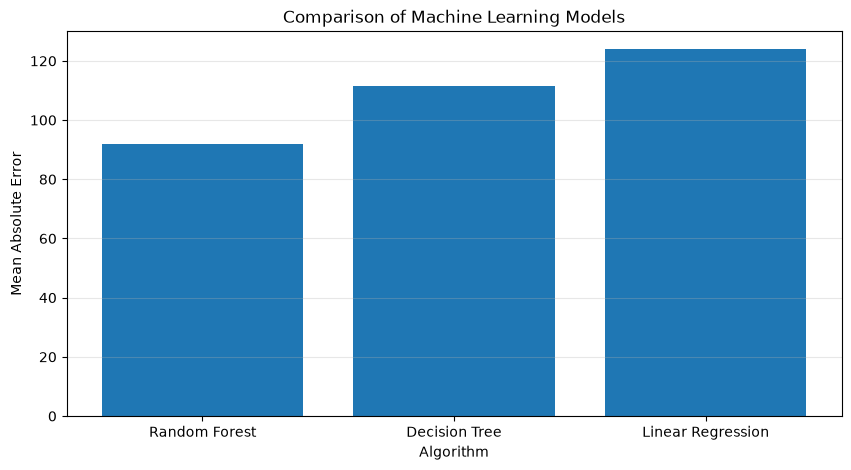

In [24]:

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Algorithm")
plt.ylabel("Mean Absolute Error")

plt.grid(axis="y", alpha=0.3)

plt.show()


In [25]:

prediction_comparison = pd.DataFrame({
    "State": test_df["state"].values,
    "Actual": y_test.values,
    "Linear Regression": linear_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
})

display(prediction_comparison.head(15))


,State,Actual,Linear Regression,Decision Tree,Random Forest
0,Andaman and Nicobar,2,10.585233,13.906977,11.480966
1,Andhra Pradesh,624,616.503801,497.500000,523.819813
2,Arunachal Pradesh,6,62.328918,31.000000,34.981172
3,Assam,173,359.724903,357.571429,357.630953
4,Bihar,358,412.137690,357.571429,365.689122
5,Chandigarh,4,20.441353,13.906977,12.636720
6,Chhattisgarh,224,334.120186,357.571429,364.525398
7,Delhi,344,214.465254,193.750000,223.076955
8,Goa,14,54.789229,31.000000,47.286624
9,Gujarat,574,904.727945,343.000000,657.225241


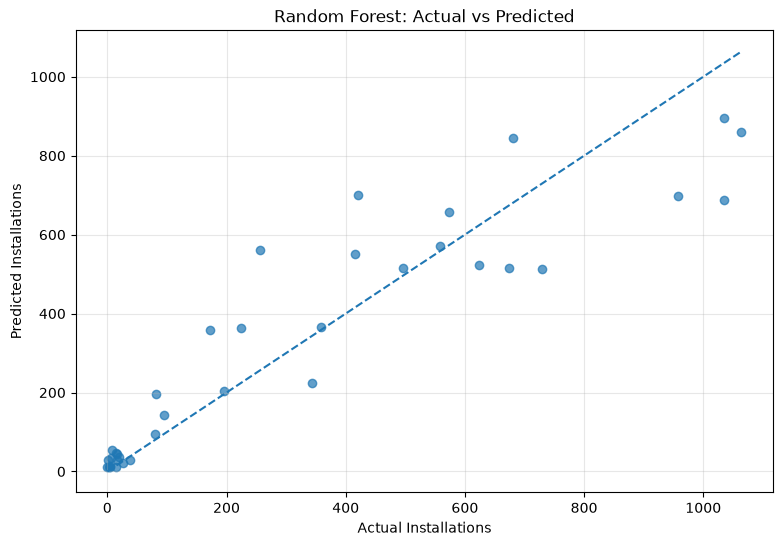

In [30]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    random_forest_predictions,
    alpha=0.7
)

max_value = max(
    y_test.max(),
    random_forest_predictions.max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Random Forest: Actual vs Predicted")
plt.xlabel("Actual Installations")
plt.ylabel("Predicted Installations")

plt.grid(alpha=0.3)
plt.show()

In [26]:

best_model_name = results_df.iloc[0]["Model"]

model_dictionary = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

best_model = model_dictionary[best_model_name]

print("Best model:", best_model_name)

display(
    results_df.iloc[0].to_frame("Best Model Results")
)


Best model: Random Forest


,Best Model Results
Model,Random Forest
MAE,91.912123
MSE,17851.198609
RMSE,133.608378
R2,0.847337


In [27]:

best_predictions = best_model.predict(X_test)

best_predictions = np.maximum(
    best_predictions,
    0
)

error_analysis = pd.DataFrame({
    "State": test_df["state"].values,
    "Actual Installations": y_test.values,
    "Predicted Installations": best_predictions
})

error_analysis["Absolute Error"] = abs(
    error_analysis["Actual Installations"]
    - error_analysis["Predicted Installations"]
)

error_analysis = error_analysis.sort_values(
    by="Absolute Error",
    ascending=False
)

display(error_analysis.head(15))


,State,Actual Installations,Predicted Installations,Absolute Error
14,Karnataka,1034,689.003889,344.996111
24,Odisha,257,559.994958,302.994958
18,Madhya Pradesh,421,700.296556,279.296556
19,Maharashtra,957,697.313389,259.686611
30,Telangana,730,513.606184,216.393816
29,Tamil Nadu,1064,860.242333,203.757667
3,Assam,173,357.630953,184.630953
27,Rajasthan,681,844.022333,163.022333
10,Haryana,674,515.791665,158.208335
6,Chhattisgarh,224,364.525398,140.525398


In [28]:

PROJECT_ROOT = ML_DATA_PATH.parents[2]

models_folder = PROJECT_ROOT / "models"
reports_folder = PROJECT_ROOT / "reports"

models_folder.mkdir(parents=True, exist_ok=True)
reports_folder.mkdir(parents=True, exist_ok=True)

# Save the best model
joblib.dump(
    best_model,
    models_folder / "best_model.joblib"
)

# Save model comparison
results_df.to_csv(
    reports_folder / "model_comparison.csv",
    index=False
)

# Save predictions
prediction_comparison.to_csv(
    reports_folder / "holdout_predictions.csv",
    index=False
)

# Save detailed errors
error_analysis.to_csv(
    reports_folder / "prediction_error_analysis.csv",
    index=False
)

print("Model and results saved successfully!")

print("\nBest Model:", best_model_name)

print("\nSaved files:")
print(list(models_folder.iterdir()))
print(list(reports_folder.iterdir()))


Model and results saved successfully!

Best Model: Random Forest

Saved files:
[PosixPath('/home/shanvi/Projects/EVChargeIQ/models/best_model.joblib')]
[PosixPath('/home/shanvi/Projects/EVChargeIQ/reports/prediction_error_analysis.csv'), PosixPath('/home/shanvi/Projects/EVChargeIQ/reports/holdout_predictions.csv'), PosixPath('/home/shanvi/Projects/EVChargeIQ/reports/model_comparison.csv')]


In [29]:

loaded_model = joblib.load(
    models_folder / "best_model.joblib"
)

sample_predictions = loaded_model.predict(
    X_test.head(5)
)

print("Saved model loaded successfully!")

print("\nSample predictions:")
print(np.maximum(sample_predictions, 0))


Saved model loaded successfully!

Sample predictions:
[ 11.4809662  523.81981339  34.98117246 357.63095312 365.68912243]



# Machine Learning Results and Conclusion

## Models Developed

Three regression algorithms were implemented:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

## Model Evaluation

The models were evaluated using:

- Mean Absolute Error
- Mean Squared Error
- Root Mean Squared Error
- R-squared

## Experimental Findings

Random Forest achieved the lowest MAE in the current dashboard's chronological holdout experiment.

Its observed metrics were:

- MAE: 91.912
- RMSE: 133.608
- R-squared: 0.847

Decision Tree and Linear Regression were also evaluated for comparison.

## Conclusion

The experiment demonstrates how historical state-wise charging infrastructure installation data can be used to train regression models for estimating subsequent-year installations.

Random Forest performed best among the three evaluated algorithms on the selected historical holdout period.

The experiment has limitations because of the small dataset and limited number of historical observations. Results should therefore be interpreted as exploratory rather than definitive forecasting performance.

The current experiment predicts FY 2024-25 installations using FY 2023-24 features. It does not establish future FY 2026-27 demand or infrastructure requirements.

## Future Scope

- Integrate VAHAN EV registration data.
- Include state-wise EV adoption growth.
- Develop a more meaningful EV-to-charger gap index.
- Include additional historical observations.
- Evaluate models using multiple chronological validation periods.
